# Ames Housing: Ridge ve Lasso Regresyon Projesi
## Bölüm 2: Veri Temizleme ve Hazırlama (Adım 2)

Bu bölümde verinin modele girmeden önce nasıl temizleneceğine karar veriyoruz. Her karar için
**neden** sorusunun cevabını yazıyoruz. Mümkün olan yerde kararı bir sayıyla (çapraz doğrulama hatası)
sınıyoruz, çünkü "mantıklı görünüyor" tek başına yeterli bir gerekçe değildir.

**Veri sızıntısı kuralı:** Veriden öğrenilen her değer (ortanca, ortalama, ölçek, kategori listesi)
yalnızca eğitim verisinden öğrenilecek. Bu yüzden hazırlık adımları `Pipeline` içinde yazılıyor.
Test kümesi ise bu bölümde yalnızca en sonda, pipeline'ın hatasız çalıştığını görmek için dönüştürülür.
Hedef değişkene hiç bakılmaz ve model eğitilmez.

**Hedef dönüşümü:** Bölüm 1'de `SalePrice` sağa çarpık çıkmıştı (1,75), logaritması ise simetrikti.
Bu yüzden modeller `log(SalePrice)` üzerinde eğitilecek. Hata değerleri bu bölümde **log ölçeğinde**
verilir (0,12 civarı, kabaca "yüzde 12 hata" demektir).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_validate

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100); pd.set_option("display.width", 140)

RANDOM_STATE = 42
TARGET = "SalePrice"

# Bölüm 1'de kaydedilen eğitim / test dosyaları ("NA" yazısı = özellik yok, bu yüzden keep_default_na=False)
train_df = pd.read_csv("ames_train.csv", keep_default_na=False, na_values=[""])
print("Eğitim kümesi:", train_df.shape)

Eğitim kümesi: (2344, 80)


### 2.1 Aykırı değerler

Bölüm 1'de `Gr Liv Area` > 4000 ft² olan 4 ev görmüştük. İkisi çok büyük olmasına rağmen çok ucuz
(`Sale Condition = Partial`, yani yeni inşa edilmiş ve tamamlanmamış ev satışı). Bu evlerin fiyatı
alanlarıyla açıklanamıyor. Diğer ikisi ise `Overall Qual = 10` ve fiyatları 745–755 bin dolar, yani
**gerçekten pahalı ve genel eğilimle uyumlu**. Bunlar hata değil, veri setinin gerçek uç noktalarıdır.

**Karar:** Yalnızca "4000 ft² üstü **ve** 300 bin doların altında" olan satırları çıkarıyoruz. Bu kural
**sadece eğitim verisine** uygulanır, test kümesine dokunulmaz.

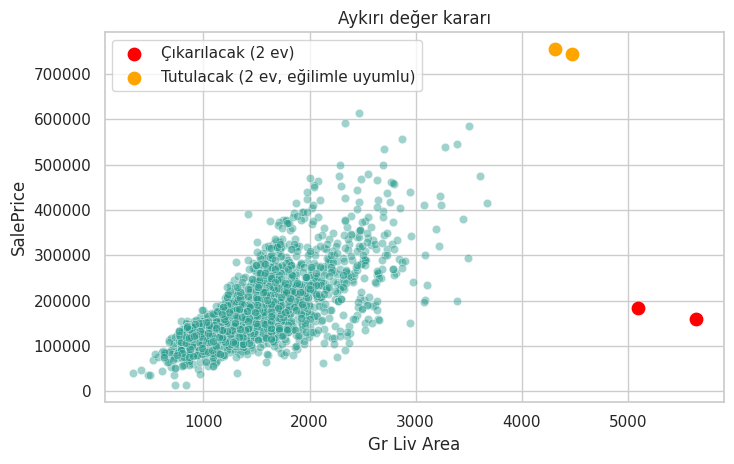

,Gr Liv Area,SalePrice,Overall Qual,Sale Condition
391,5642,160000,10,Partial
451,4476,745000,10,Abnorml
915,4316,755000,10,Normal
1634,5095,183850,10,Partial


In [2]:
is_outlier = (train_df["Gr Liv Area"] > 4000) & (train_df[TARGET] < 300_000)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.scatterplot(data=train_df[~is_outlier], x="Gr Liv Area", y=TARGET, alpha=0.45, color="#2a9d8f", ax=ax)
ax.scatter(train_df.loc[is_outlier, "Gr Liv Area"], train_df.loc[is_outlier, TARGET],
           color="red", s=80, label=f"Çıkarılacak ({is_outlier.sum()} ev)")
big_ok = (train_df["Gr Liv Area"] > 4000) & ~is_outlier
ax.scatter(train_df.loc[big_ok, "Gr Liv Area"], train_df.loc[big_ok, TARGET],
           color="orange", s=80, label=f"Tutulacak ({big_ok.sum()} ev, eğilimle uyumlu)")
ax.set_title("Aykırı değer kararı"); ax.legend(); plt.tight_layout(); plt.show()

display(train_df.loc[is_outlier | big_ok, ["Gr Liv Area", TARGET, "Overall Qual", "Sale Condition"]])

### 2.2 Eksik değerler, tipler ve tutarsız kayıtlar

Bölüm 1'de eksik verinin iki farklı anlamı olduğunu görmüştük. Aşağıdaki tablo tüm kararları özetliyor.

| Durum | Sütunlar | Karar | Gerekçe |
|---|---|---|---|
| `NA` yazısı (özellik yok) | `Alley`, `Fence`, `Fireplace Qu`, garaj ve bodrum kategorikleri, `Misc Feature`, `Pool QC` | `"None"` kategorisi | Evde o özellik yok. Bu bilgi fiyat için anlamlı, silinemez veya ortalamayla doldurulamaz |
| Boş + sayısal ve yapısal | `Mas Vnr Area`, bodrum alanları ve banyoları, `Garage Cars`, `Garage Area` | `0` | Özellik yoksa alanı sıfırdır |
| `Garage Yr Blt` boş | 122 satır (garajsız evler) | `Year Built` ile doldur | Garaj yoksa yıl da yok. Evin yapım yılı makul ve tarafsız bir yedek değer |
| `Garage Yr Blt` = 2207 | 1 satır | `Year Built` ile değiştir | Açık bir yazım hatası (tarih gelecekte) |
| `Lot Frontage` boş | %16,8 | **Mahalle ortancası** (eğitimden öğrenilir) | Gerçek eksik bilgi. Aynı mahalledeki evlerin parselleri benzerdir |
| `Electrical` boş | test kümesinde 1 satır | En sık değer (pipeline içinde) | Tek satır, önemsiz |
| `MS SubClass` (sayı) | tüm satırlar | Kategorik (metin) | 20, 30, 40… bir sıra değil, bir sınıf kodudur |
| `Mo Sold` (sayı) | tüm satırlar | Kategorik (metin) | Ay numarası döngüseldir (Aralık ile Ocak komşudur) |

Not: `Year Built`, `Year Remod/Add` ve `Yr Sold` arasında birkaç mantıksız kayıt var (örneğin satış yılı
yapım yılından önce). Sayıları 1'er satırdır, etkileri ihmal edilebilir. Bu kayıtlara dokunmuyoruz.

In [3]:
# --- Sabit listeler (alan bilgisine dayanır, veriden öğrenilmez) ---
QUAL = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDINAL_MAPS = {c: QUAL for c in ["Exter Qual", "Exter Cond", "Bsmt Qual", "Bsmt Cond", "Heating QC",
                                  "Kitchen Qual", "Fireplace Qu", "Garage Qual", "Garage Cond", "Pool QC"]}
ORDINAL_MAPS.update({
    "Bsmt Exposure":  {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFin Type 1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFin Type 2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "Garage Finish":  {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Functional":     {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "Land Slope":     {"Sev": 0, "Mod": 1, "Gtl": 2},
    "Lot Shape":      {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Paved Drive":    {"N": 0, "P": 1, "Y": 2},
    "Central Air":    {"N": 0, "Y": 1},
})
# Eğitim kümesinde tek bir değerin %98'den fazlasını oluşturduğu sütunlar (Bölüm 1, madde 1.10)
NEAR_CONSTANT = ["Street", "Utilities", "Condition 2", "Roof Matl", "Heating", "Pool QC"]
# Çarpık, sürekli alan sütunları (2.4'te gösterilecek)
LOG_COLS = ["Lot Area", "Lot Frontage", "1st Flr SF", "Gr Liv Area", "BsmtFin SF 1", "Open Porch SF"]
LOG_REJECTED = ["Total Bsmt SF"]   # 2.4'te elenme gerekçesi gösterilecek
ZERO_FILL = ["Mas Vnr Area", "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF",
             "Bsmt Full Bath", "Bsmt Half Bath", "Garage Cars", "Garage Area"]


def clean_static(X, ordinal=True, drop_const=True):
    """Veriden hiçbir şey öğrenmeyen (durumsuz) temizlik. Satır satır uygulanır, sızıntı riski yoktur."""
    X = X.copy()
    cat = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    for c in cat:
        X[c] = X[c].replace("NA", "None")           # "NA" yazısı = özellik yok
        if c != "Electrical":                       # Electrical'in tek eksiği pipeline'da doldurulur
            X[c] = X[c].fillna("None")
    for c in ZERO_FILL:
        X[c] = X[c].fillna(0)
    gy = X["Garage Yr Blt"]                          # boş (garaj yok) veya 2207 (yazım hatası)
    X["Garage Yr Blt"] = gy.where(~(gy.isna() | (gy > 2010)), X["Year Built"])
    X["MS SubClass"] = X["MS SubClass"].astype(str)  # sınıf kodu, sayı değil
    X["Mo Sold"] = X["Mo Sold"].astype(str)
    if ordinal:                                      # sıralı kategoriler -> 0,1,2,...
        for c, m in ORDINAL_MAPS.items():
            X[c] = X[c].map(m).fillna(0).astype(float)
    if drop_const:
        X = X.drop(columns=NEAR_CONSTANT)
    return X


X_all = train_df.drop(columns=TARGET)
before = X_all.isna().sum().sum()
after = clean_static(X_all).drop(columns="Electrical").isna().sum().sum()
lot_left = clean_static(X_all)["Lot Frontage"].isna().sum()
print(f"Temizlikten önce toplam boş hücre            : {before}")
print(f"Temizlikten sonra kalan (Electrical hariç)    : {after}  (hepsi Lot Frontage: {lot_left})")

Temizlikten önce toplam boş hücre            : 573
Temizlikten sonra kalan (Electrical hariç)    : 393  (hepsi Lot Frontage: 393)


### 2.3 `Lot Frontage` (cadde cephesi) için mahalle ortancası

Bu, tek **gerçek** eksik değer sütunudur (eğitimde 393 satır, %16,8). Ortalamadan çok ortanca
tercih edilir, çünkü sütun sağa çarpıktır. Mahalleye göre doldurmanın nedeni, parsel boyutlarının
mahalleden mahalleye değişmesidir. Aşağıdaki grafik bunu gösteriyor.

Ortancayı **eğitim verisinden öğrenen** ve test/doğrulama verisine uygulayan özel bir dönüştürücü
yazıyoruz. Böylece her çapraz doğrulama katında ortanca sadece o katın eğitim kısmından hesaplanır.

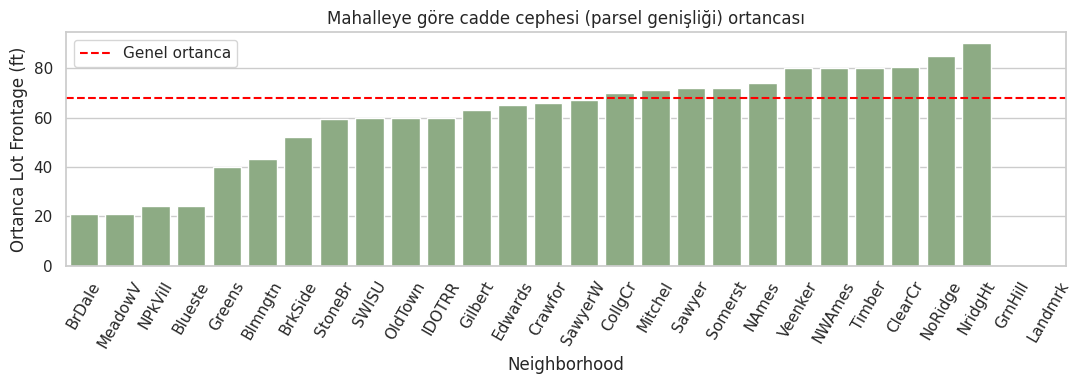

In [4]:
class GroupMedianImputer(BaseEstimator, TransformerMixin):
    """Bir sütundaki eksikleri, grup (mahalle) ortancasıyla doldurur. Ortancayı fit sırasında öğrenir."""
    def __init__(self, column="Lot Frontage", group="Neighborhood", use_group=True):
        self.column = column; self.group = group; self.use_group = use_group
    def fit(self, X, y=None):
        self.global_median_ = X[self.column].median()
        if self.use_group:
            self.group_medians_ = X.groupby(self.group)[self.column].median()
        return self
    def transform(self, X):
        X = X.copy()
        if self.use_group:
            fill = X[self.group].map(self.group_medians_).fillna(self.global_median_)
        else:
            fill = self.global_median_
        X[self.column] = X[self.column].fillna(fill)
        return X


med = train_df.groupby("Neighborhood")["Lot Frontage"].median().sort_values()
plt.figure(figsize=(11, 4))
sns.barplot(x=med.index, y=med.values, color="#8ab17d")
plt.axhline(train_df["Lot Frontage"].median(), color="red", ls="--", label="Genel ortanca")
plt.xticks(rotation=60); plt.ylabel("Ortanca Lot Frontage (ft)"); plt.legend()
plt.title("Mahalleye göre cadde cephesi (parsel genişliği) ortancası"); plt.tight_layout(); plt.show()

### 2.4 Çarpık sayısal sütunlar ve ölçekleme

**Ölçekleme (zorunlu):** Ridge ve Lasso ceza terimi katsayıların büyüklüğüne bakar. Sütunlar farklı
ölçeklerdeyse (`Lot Area` on binlerle, banyo sayısı 1–3 arası) ceza adil dağılmaz ve büyük ölçekli
sütunlar kayırılır. Bu yüzden her sayısal sütun `StandardScaler` ile ortalaması 0, standart sapması 1
olacak şekilde ölçeklenir. One-Hot (0/1) sütunlara dokunulmaz, çünkü zaten aynı aralıktadırlar.

**Log dönüşümü:** Alan sütunlarının çoğu sağa çarpıktır (örneğin `Lot Area` çarpıklığı 13,7).
Alan ve fiyat ilişkisi çarpımsaldır ("alan %10 artınca fiyat yaklaşık %x artar"), bu yüzden `log1p`
doğrusal modele daha uygundur. Kuralımız: çarpıklığı 1'den büyük olan, sayı (adet) veya yıl
olmayan, değerlerinin yarısından azı sıfır olan alan sütunları **ve** log sonrası çarpıklığın mutlak
değeri ham değerden küçük olan sütunlar. Bunlar 6 sütundur.

`Total Bsmt SF` ilk koşulları sağlıyor ama listeye **girmiyor**: bodrumsuz birkaç ev (değer 0) log
sonrası aşırı düşük değerlere dönüşüyor ve çarpıklık 1,34'ten -5,05'e **kötüleşiyor**. Bunu aşağıdaki tabloda
"ELENDİ" olarak işaretledik. Hatadaki etkisini 2.7'nin sonunda ayrıca ölçüyoruz.

,Çarpıklık (ham),Çarpıklık (log1p),Sıfır oranı,Karar
Sütun,,,,
Lot Area,13.74,-0.48,0.00,log uygulanır
Lot Frontage,1.77,-0.97,0.00,log uygulanır
1st Flr SF,1.54,0.06,0.00,log uygulanır
Gr Liv Area,1.30,0.02,0.00,log uygulanır
BsmtFin SF 1,1.53,-0.64,0.31,log uygulanır
Open Porch SF,2.66,-0.03,0.45,log uygulanır
Total Bsmt SF,1.34,-5.05,0.03,ELENDİ (log kötüleştiriyor)


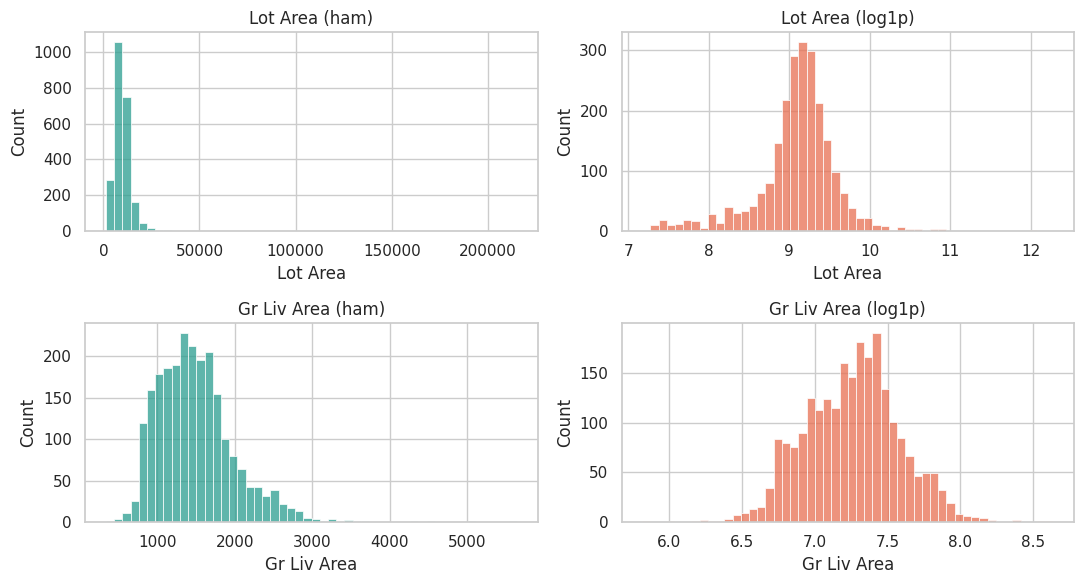

In [5]:
tmp = clean_static(train_df.drop(columns=TARGET))
tmp = GroupMedianImputer().fit(tmp).transform(tmp)

rows = []
for c in LOG_COLS + LOG_REJECTED:
    rows.append({"Sütun": c, "Çarpıklık (ham)": tmp[c].skew(), "Çarpıklık (log1p)": np.log1p(tmp[c]).skew(),
                 "Sıfır oranı": (tmp[c] == 0).mean(), "Karar": "log uygulanır" if c in LOG_COLS else "ELENDİ (log kötüleştiriyor)"})
display(pd.DataFrame(rows).set_index("Sütun").round(2))

fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for i, c in enumerate(["Lot Area", "Gr Liv Area"]):
    sns.histplot(tmp[c], bins=50, ax=ax[i, 0], color="#2a9d8f"); ax[i, 0].set_title(f"{c} (ham)")
    sns.histplot(np.log1p(tmp[c]), bins=50, ax=ax[i, 1], color="#e76f51"); ax[i, 1].set_title(f"{c} (log1p)")
plt.tight_layout(); plt.show()

### 2.5 Kategorik kodlama

- **Sıralı (ordinal) kodlama:** Kalite sütunları (`Exter Qual`, `Kitchen Qual`, `Bsmt Qual` vb.:
  Yok < Po < Fa < TA < Gd < Ex) ve sıralı doğası olan diğerleri (`Bsmt Exposure`, `Garage Finish`,
  `Functional`, `Lot Shape`...) 0, 1, 2... sayılarına çevrilir. Böylece hem bilgi ("Gd, TA'dan iyidir") korunur
  hem de 5–6 One-Hot sütun yerine 1 sütun kullanılır. Toplam 19 sütun bu şekilde kodlanıyor (biri, `Pool QC`, aşağıda sabit sütun olarak çıkarılır).
- **One-Hot kodlama:** Sırası olmayan sütunlar (`Neighborhood`, `MS Zoning`, `House Style`...).
  `min_frequency=10` ile eğitimde 10'dan az görülen nadir kategoriler tek bir "nadir" sütununda
  toplanır. Çok nadir bir kategori için katsayı öğrenmek ezberlemeye yol açar. Test verisinde görülmemiş
  bir kategori çıkarsa hata vermez, "nadir" grubuna girer.
- **Neredeyse sabit sütunlar:** `Street`, `Utilities`, `Condition 2`, `Roof Matl`, `Heating`, `Pool QC`
  (satırların %98'inden fazlasında aynı değer) modele bilgi katmaz, 6 sütun çıkarılır.

### 2.6 Pipeline'ın kurulması

Tüm adımlar tek bir `Pipeline` içinde birleşiyor:

`temizlik (durumsuz)` → `Lot Frontage ortanca doldurma` → `sütun grubuna göre dönüştürme`
(log+ölçek / ölçek / eksik doldurma+One-Hot) → `model`

Fonksiyon, her kararı bir bayrakla açıp kapatabiliyor. Bu, bir sonraki bölümde her kararın
etkisini ölçmemizi sağlayacak.

In [6]:
def make_pipeline(model, X_ref, group_impute=True, ordinal=True, log_skew=True, drop_const=True):
    # Sütun gruplarını yalnızca isimlerden belirliyoruz (hiçbir değer öğrenilmiyor)
    ref = clean_static(X_ref, ordinal, drop_const)
    num_cols = [c for c in ref.columns if pd.api.types.is_numeric_dtype(ref[c])]
    cat_cols = [c for c in ref.columns if c not in num_cols]
    log_cols = [c for c in LOG_COLS if c in num_cols] if log_skew else []
    plain = [c for c in num_cols if c not in log_cols]

    ct = ColumnTransformer([
        ("log", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("sc", StandardScaler())]), log_cols),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), plain),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                min_frequency=10, sparse_output=False))]), cat_cols),
    ])
    return Pipeline([
        ("clean", FunctionTransformer(clean_static, kw_args=dict(ordinal=ordinal, drop_const=drop_const))),
        ("lot", GroupMedianImputer(use_group=group_impute)),
        ("prep", ct),
        ("model", model),
    ])


# Aykırı değerleri yalnızca eğitim verisinden çıkarıyoruz (2.1'deki karar)
train_clean = train_df[~is_outlier].reset_index(drop=True)
X_tr = train_clean.drop(columns=TARGET)
y_tr = np.log(train_clean[TARGET])
print("Aykırı değerler çıkarıldıktan sonra eğitim:", X_tr.shape)

Aykırı değerler çıkarıldıktan sonra eğitim: (2342, 79)


### 2.7 Kararların etkisini ölçme (ablasyon)

Her hazırlık kararını sırayla ekleyip 5 katlı çapraz doğrulama hatasına bakıyoruz. Model olarak
sabit alfa'lı bir Ridge kullanıyoruz. **Bu, modeli ayarlamak değil, hazırlık kararlarını karşılaştırmak içindir.**
Alfa'nın ayarlanması Adım 6'da yapılacak. Sonuçların alfa'ya bağlı olmadığını görmek için üç farklı alfa
deniyoruz.

Hata ölçüsü: log fiyat üzerinde RMSE (düşük olan iyi), R² (yüksek olan iyi).

,RMSE (α=3),RMSE (α=10),R² (α=10),Fold std (α=10),RMSE (α=30),Özellik sayısı
Adım,,,,,,
A. Temel (NA işlemi + sınıf kodları),0.1198,0.1182,0.9122,0.0096,0.1178,298
B. + Mahalle ortancası (Lot Frontage),0.1199,0.1182,0.9121,0.0096,0.1179,298
C. + Sıralı kodlama,0.1187,0.1175,0.9130,0.0080,0.1175,228
D. + Log dönüşümü (6 alan sütunu),0.1156,0.1145,0.9174,0.0077,0.1147,228
E. + Sabit sütunları çıkar,0.1155,0.1147,0.9172,0.0076,0.1148,214


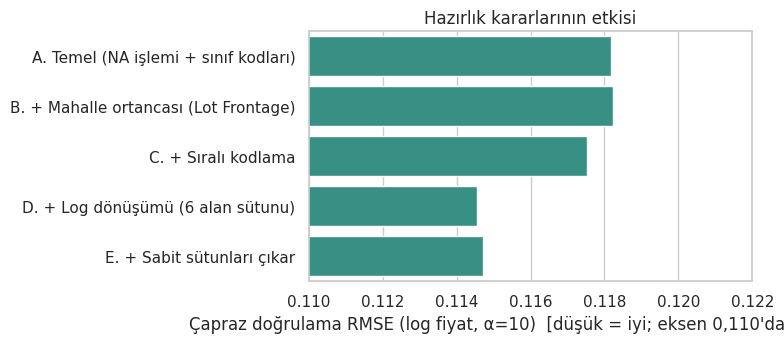

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

steps = [
    ("A. Temel (NA işlemi + sınıf kodları)", dict(group_impute=False, ordinal=False, log_skew=False, drop_const=False)),
    ("B. + Mahalle ortancası (Lot Frontage)", dict(group_impute=True,  ordinal=False, log_skew=False, drop_const=False)),
    ("C. + Sıralı kodlama",                   dict(group_impute=True,  ordinal=True,  log_skew=False, drop_const=False)),
    ("D. + Log dönüşümü (6 alan sütunu)",     dict(group_impute=True,  ordinal=True,  log_skew=True,  drop_const=False)),
    ("E. + Sabit sütunları çıkar",            dict(group_impute=True,  ordinal=True,  log_skew=True,  drop_const=True)),
]

rows = []
for name, kw in steps:
    row = {"Adım": name}
    for alpha in (3, 10, 30):
        p = make_pipeline(Ridge(alpha=alpha), X_tr, **kw)
        r = cross_validate(p, X_tr, y_tr, cv=kf, scoring=("neg_root_mean_squared_error", "r2"))
        row[f"RMSE (α={alpha})"] = -r["test_neg_root_mean_squared_error"].mean()
        if alpha == 10:
            row["R² (α=10)"] = r["test_r2"].mean()
            row["Fold std (α=10)"] = r["test_neg_root_mean_squared_error"].std()
    row["Özellik sayısı"] = make_pipeline(Ridge(alpha=10), X_tr, **kw).fit(X_tr, y_tr)[:-1].transform(X_tr).shape[1]
    rows.append(row)

ablation = pd.DataFrame(rows).set_index("Adım")
display(ablation.round(4))

plt.figure(figsize=(8, 3.6))
sns.barplot(y=ablation.index, x=ablation["RMSE (α=10)"], color="#2a9d8f")
plt.xlim(0.110, 0.122); plt.xlabel("Çapraz doğrulama RMSE (log fiyat, α=10)  [düşük = iyi; eksen 0,110'dan başlıyor]"); plt.ylabel("")
plt.title("Hazırlık kararlarının etkisi"); plt.tight_layout(); plt.show()

**Yorum:**
- Hazırlık kararları birlikte hatayı **0,1182'den 0,1147'ye** düşürüyor. Üç farklı alfa için sıralama aynı
  kalıyor.
- Dürüst bir uyarı: tek tek adımların farkı, katlar arası değişimden (std ≈ 0,008–0,010) **küçük**. Bu yüzden
  hiçbir adımın "kesin olarak anlamlı" olduğunu iddia etmiyoruz. Bu adımları tutmamızın nedeni, zarar
  vermemeleri, kuramsal olarak doğru olmaları ve etkilerinin tüm alfa değerlerinde aynı yönde olmasıdır.
- **Mahalle ortancası (B)** ölçülebilir bir fark yaratmadı. Yine de tutuyoruz, çünkü genel ortancadan
  daha mantıklı ve maliyeti yok.
- **Sıralı kodlama (C)** hatayı biraz düşürdü ve özellik sayısını **298'den 228'e** indirdi.
- **Log dönüşümü (D)** en büyük tek adım: 0,1175 → 0,1145 (üç alfa için de yaklaşık 0,003 iyileşme).
- **Sabit sütunlar (E)** hatayı pratikte değiştirmedi (0,1145 → 0,1147), ama 14 sütun daha kaldırdı
  (214 özellik). Model daha sade ve yorumlaması daha kolay.

**Küçük bir sınama:** `Total Bsmt SF`'i log listesine eklersek ne olur? (2.4'teki eleme kararının doğrulaması)

In [8]:
orig_log_cols = LOG_COLS.copy()
rows = []
try:
    for label, cols in [("Total Bsmt SF log DIŞI (seçtiğimiz)", orig_log_cols),
                        ("Total Bsmt SF log İÇİNDE", orig_log_cols + ["Total Bsmt SF"])]:
        LOG_COLS[:] = cols
        p = make_pipeline(Ridge(alpha=10), X_tr)
        r = cross_validate(p, X_tr, y_tr, cv=kf, scoring="neg_root_mean_squared_error")
        rows.append({"Yapılandırma": label, "RMSE (α=10)": -r["test_score"].mean()})
finally:
    LOG_COLS[:] = orig_log_cols
display(pd.DataFrame(rows).set_index("Yapılandırma").round(4))

,RMSE (α=10)
Yapılandırma,
Total Bsmt SF log DIŞI (seçtiğimiz),0.1147
Total Bsmt SF log İÇİNDE,0.1168


### 2.8 Aykırı değer kararını sınama

2.1'deki karar gerçekten işe yarıyor mu? Test edelim. Her çapraz doğrulama katında modeli
(a) aykırı değerler **dahil**, (b) aykırı değerler **hariç** eğitiyor ve ikisini de aynı
doğrulama satırlarında (aykırı olmayanlar) değerlendiriyoruz. Böylece karşılaştırma adil.

In [9]:
X_full = train_df.drop(columns=TARGET)
y_full = np.log(train_df[TARGET])
out_arr = is_outlier.values

rows = []
for log in (False, True):
    res = {"dahil": [], "hariç": []}
    for tri, vai in kf.split(X_full):
        vai_ok = vai[~out_arr[vai]]
        for key in res:
            idx = tri if key == "dahil" else tri[~out_arr[tri]]
            p = make_pipeline(Ridge(alpha=10), X_full, log_skew=log).fit(X_full.iloc[idx], y_full.iloc[idx])
            err = p.predict(X_full.iloc[vai_ok]) - y_full.iloc[vai_ok]
            res[key].append(np.sqrt(np.mean(err ** 2)))
    rows.append({"Log dönüşümü": "Var" if log else "Yok",
                 "RMSE (aykırı dahil)": np.mean(res["dahil"]), "RMSE (aykırı hariç)": np.mean(res["hariç"])})
display(pd.DataFrame(rows).set_index("Log dönüşümü").round(4))

,RMSE (aykırı dahil),RMSE (aykırı hariç)
Log dönüşümü,,
Yok,0.1272,0.1183
Var,0.1215,0.1158


**Yorum:** İki aykırı evi eğitimden çıkarmak hatayı belirgin biçimde düşürüyor: log dönüşümü yokken
0,127 → 0,118, log dönüşümü varken 0,122 → 0,116. Bunun nedeni, bu iki evin çok büyük `Gr Liv Area`
değerleriyle regresyon doğrusunu kendi tarafına çeken "kaldıraç" noktaları olmasıdır. Bu, hazırlık
kararları arasında **en etkili adımlardan biridir**.

Log dönüşümünün katkısı da ilginç: aykırı değerler **varken** daha büyük (0,127 → 0,122), çıkarıldıktan
sonra yaklaşık yarıya iniyor ama sürüyor (0,118 → 0,116). Yani log dönüşümü kısmen aykırı değerlerin
etkisini bastırıyor, kısmen de alan–fiyat ilişkisini gerçekten doğrusallaştırıyor.

Not: Değerler farklı doğrulama kümelerinde ölçüldüğü için 2.7 tablosundaki sayılarla doğrudan
karşılaştırılmamalı.

### 2.9 Son kontrol: hazırlanmış verinin yapısı

In [10]:
final = make_pipeline(Ridge(alpha=10), X_tr)
final.fit(X_tr, y_tr)
Z_tr = final[:-1].transform(X_tr)
names = final.named_steps["prep"].get_feature_names_out()

print("Eğitim, dönüştürülmüş boyut:", Z_tr.shape)
print("Kalan eksik değer sayısı   :", int(np.isnan(Z_tr).sum()))

grp = pd.Series([n.split("__")[0] for n in names]).value_counts()
print("\nÖzellik grupları (log / num / cat):"); print(grp.to_string())

num_idx = [i for i, n in enumerate(names) if not n.startswith("cat__")]
print(f"\nÖlçeklenmiş sayısal sütunlar: ortalama ≈ {Z_tr[:, num_idx].mean():.3f}, std ≈ {Z_tr[:, num_idx].std():.3f}")
print("\nİlk 8 özellik adı:", list(names[:8]))

# Test kümesi: hedef hiç kullanılmıyor. Yalnızca pipeline'ın hatasız çalıştığını doğruluyoruz.
test_df = pd.read_csv("ames_test.csv", keep_default_na=False, na_values=[""])
Z_te = final[:-1].transform(test_df.drop(columns=TARGET))
print("\nTest, dönüştürülmüş boyut:", Z_te.shape, "| eksik değer:", int(np.isnan(Z_te).sum()))

Eğitim, dönüştürülmüş boyut: (2342, 214)
Kalan eksik değer sayısı   : 0

Özellik grupları (log / num / cat):
cat    162
num     46
log      6

Ölçeklenmiş sayısal sütunlar: ortalama ≈ -0.000, std ≈ 1.000

İlk 8 özellik adı: ['log__Lot Area', 'log__Lot Frontage', 'log__1st Flr SF', 'log__Gr Liv Area', 'log__BsmtFin SF 1', 'log__Open Porch SF', 'num__Lot Shape', 'num__Land Slope']

Test, dönüştürülmüş boyut: (586, 214) | eksik değer: 0


### 2.10 Bölüm 2 özeti (raporun "Veri hazırlama" bölümü için)

| # | Karar | Gerekçe | Ölçülen etki |
|---|---|---|---|
| 1 | 2 aykırı evi eğitimden çıkar (>4000 ft² ve <300 bin $) | Alanıyla açıklanamayan, tamamlanmamış satışlar. Regresyon doğrusunu çekiyorlar | **Büyük etki**: RMSE 0,122 → 0,116 (log varken) |
| 2 | `NA` yazısı → `"None"` kategorisi | Özellik yok anlamına gelir, eksik veri değildir | Bilgi kaybını önler |
| 3 | Yapısal boşluklar (alan, banyo) → 0, `Garage Yr Blt` → yapım yılı | Özellik yoksa değeri sıfırdır | Doğruluk, 2207 hatası düzeltilir |
| 4 | `Lot Frontage` → mahalle ortancası (eğitimden öğrenilir) | Gerçek eksik, parsel boyutu mahalleye bağlı | Ölçülebilir fark yok, tutuldu |
| 5 | `MS SubClass`, `Mo Sold` → kategorik | Sayı gibi görünen kodlar | Yanlış sıralı ilişkiyi önler |
| 6 | 19 sütun sıralı kodlama (18'i kalır), kalanlar One-Hot (`min_frequency=10`) | Sıra bilgisini korur, özelliği azaltır | 298 → 228 özellik, RMSE 0,1182 → 0,1175 |
| 7 | 6 çarpık alan sütununa `log1p` (`Total Bsmt SF` elendi) | Alan–fiyat ilişkisi çarpımsal, çarpıklık azalır | RMSE 0,1175 → 0,1145 |
| 8 | 6 neredeyse sabit sütunu çıkar | Bilgi katmaz | 228 → 214 özellik, hata pratikte aynı |
| 9 | Sayısal sütunlara `StandardScaler` | Ridge/Lasso cezası ölçeğe duyarlı | Zorunlu |
| 10 | Hedef: `log(SalePrice)` | Çarpıklık 1,75 → -0,09, hata yüzde cinsinden | Bölüm 1 |

**Sonuç:** Eğitim kümesi 2342 satır, hazırlık sonrası 214 özellik. Tüm adımlar Pipeline içinde,
test kümesine hiç bakılmadı.

**Sonraki adım (Bölüm 3):** özellik üretimi (en az 2 yeni özellik) ve özellik seçimi.